# Project 9 — Visual Defect and Anomaly Detection

A different formulation from everything else in this module: you train on
**normal examples only**. The network never sees a labelled defect. It learns
to rebuild normal products, and then rebuilds a defective one *as though it
were normal* — the difference between input and reconstruction is the signal.

That means the threshold cannot come from labelled defects. It comes from the
distribution of reconstruction errors on normal validation images, which is
what lets you state an expected false-alarm rate before you have seen a
single fault.

In [ ]:
# --- 1. Setup --------------------------------------------------------------
import json, random, shutil, time
from datetime import date
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

from google.colab import drive
drive.mount('/content/drive')
WORK = Path('/content/drive/MyDrive/dl-project-09'); WORK.mkdir(parents=True, exist_ok=True)

Device: cuda
Mounted at /content/drive


## 2. Dataset

**MVTec AD** is the standard benchmark. It is free for non-commercial
research and teaching, but you must accept the licence and download it
yourself — there is no automatic download, and that is deliberate.

1. Go to `https://www.mvtec.com/company/research/datasets/mvtec-ad`
2. Accept the licence and download one category (bottle, hazelnut, screw...)
3. Upload it to `MyDrive/dl-project-09/data/` keeping the folder structure:

```
data/<category>/
  train/good/           normal images only
  test/good/            normal test images
  test/<defect_type>/   defective test images
```

**YOU DECIDE** which category, and justify it. Pick one and do it properly.

In [ ]:
CATEGORY = 'bottle'
DATA = WORK / 'data' / CATEGORY

# Synthetic fallback so the notebook runs today. It generates "normal" textured
# discs and "defective" ones with a scratch. DELETE once MVTec AD is in place.
if not DATA.exists():
    print("MVTec AD not found — generating a synthetic stand-in dataset.")

    def make_product(defective=False, size=256):
        image = Image.new('RGB', (size, size), (208, 210, 214))
        draw = ImageDraw.Draw(image)
        centre = size // 2
        draw.ellipse((centre - 84, centre - 84, centre + 84, centre + 84),
                     fill=(150, 158, 170), outline=(112, 120, 132), width=3)
        for _ in range(60):                      # texture, so reconstruction is non-trivial
            x, y = random.randint(0, size - 1), random.randint(0, size - 1)
            draw.point((x, y), fill=(random.randint(120, 200),) * 3)
        if defective:
            kind = random.choice(['scratch', 'chip', 'stain'])
            if kind == 'scratch':
                x = random.randint(centre - 50, centre + 10)
                draw.line((x, centre - 40, x + random.randint(30, 70), centre + 30),
                          fill=(46, 32, 28), width=random.randint(3, 6))
            elif kind == 'chip':
                x, y = random.randint(centre - 60, centre + 40), random.randint(centre - 60, centre + 40)
                draw.ellipse((x, y, x + 26, y + 22), fill=(90, 70, 60))
            else:
                x, y = random.randint(centre - 50, centre + 30), random.randint(centre - 50, centre + 30)
                draw.ellipse((x, y, x + 40, y + 36), fill=(128, 128, 110))
        return image.filter(ImageFilter.GaussianBlur(0.4))

    for folder, count, defective in [('train/good', 220, False), ('test/good', 40, False),
                                     ('test/defect', 40, True)]:
        target = DATA / folder; target.mkdir(parents=True, exist_ok=True)
        for i in range(count):
            make_product(defective).save(target / f'{i:03d}.png')

train_paths = sorted((DATA / 'train' / 'good').glob('*.*'))
test_normal = sorted((DATA / 'test' / 'good').glob('*.*'))
test_defect = [p for folder in (DATA / 'test').iterdir() if folder.is_dir() and folder.name != 'good'
               for p in sorted(folder.glob('*.*'))]

print(f"train (normal only) {len(train_paths)}")
print(f"test normal         {len(test_normal)}")
print(f"test defective      {len(test_defect)}")
assert train_paths and test_normal and test_defect, "Check your folder structure."

MVTec AD not found — generating a synthetic stand-in dataset.
train (normal only) 220
test normal         40
test defective      40


In [ ]:
CONFIG = {
    "task": "anomaly_detection",
    "architecture": "conv_autoencoder",
    "category": CATEGORY,
    "input_size": [128, 128],
    "base_channels": 32,
    "latent_channels": 128,
    "depth": 4,
    "scoring_rule": "mean",           # compared against "max_patch" below
    "patch_size": 16,
    "anomaly_threshold": 0.0,         # derived from validation normals
    "trained_on": str(date.today()),
}
BATCH_SIZE, EPOCHS = 32, 40

# No ImageNet normalisation: the decoder ends in a sigmoid producing [0, 1], so
# the input must be in [0, 1] too. Normalising the input but not the target is
# a classic mistake here — the loss then never drops properly.
transform = transforms.Compose([
    transforms.Resize(CONFIG["input_size"]),
    transforms.ToTensor(),
])


class ImageListDataset(Dataset):
    def __init__(self, paths, transform):
        self.paths, self.transform = list(paths), transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        return self.transform(Image.open(self.paths[index]).convert('RGB')), str(self.paths[index])


# Hold back some NORMAL training images for validation: they are what sets the
# threshold. Defective images are never used for fitting anything.
split = int(0.85 * len(train_paths))
fit_paths, validation_paths = train_paths[:split], train_paths[split:]

train_loader = DataLoader(ImageListDataset(fit_paths, transform),
                          batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
validation_loader = DataLoader(ImageListDataset(validation_paths, transform),
                               batch_size=BATCH_SIZE, num_workers=2)
print(f"fit {len(fit_paths)}   validation-normal {len(validation_paths)}")

fit 187   validation-normal 33


In [ ]:
# The architecture, identical to src/model.py in the application.
def encoder_block(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 4, 2, 1), nn.BatchNorm2d(cout), nn.ReLU(True))

def decoder_block(cin, cout):
    return nn.Sequential(nn.ConvTranspose2d(cin, cout, 4, 2, 1), nn.BatchNorm2d(cout), nn.ReLU(True))

class ConvAutoencoder(nn.Module):
    def __init__(self, base_channels=32, latent_channels=128, depth=4):
        super().__init__()
        channels = [3] + [base_channels * (2 ** i) for i in range(depth - 1)] + [latent_channels]
        self.encoder = nn.Sequential(*[encoder_block(channels[i], channels[i + 1]) for i in range(depth)])
        reverse = channels[::-1]
        self.decoder = nn.Sequential(
            *[decoder_block(reverse[i], reverse[i + 1]) for i in range(depth - 1)],
            nn.ConvTranspose2d(reverse[depth - 1], 3, 4, 2, 1), nn.Sigmoid())

    def forward(self, x):
        return self.decoder(self.encoder(x))


model = ConvAutoencoder(CONFIG["base_channels"], CONFIG["latent_channels"], CONFIG["depth"]).to(DEVICE)
optimiser = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.MSELoss()
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

856,771 parameters


## 3. Train on normal images only

Watch the **validation reconstruction error on normal images**. It should
fall and then flatten. If it keeps falling towards zero, the bottleneck is
too wide: the network is learning to copy pixels, and it will reconstruct
defects perfectly too — detecting nothing.

epoch   1  train 0.07986  val 0.06722  (3s)  <- saved
epoch   2  train 0.04293  val 0.04404  (1s)  <- saved
epoch   4  train 0.01032  val 0.01305  (1s)  <- saved
epoch   6  train 0.00237  val 0.01389  (1s)
epoch   8  train 0.00144  val 0.00468  (1s)  <- saved
epoch  10  train 0.00112  val 0.00157  (1s)  <- saved
epoch  12  train 0.00095  val 0.00095  (2s)  <- saved
epoch  14  train 0.00084  val 0.00087  (2s)  <- saved
epoch  16  train 0.00077  val 0.00078  (1s)  <- saved
epoch  18  train 0.00071  val 0.00071  (1s)  <- saved
epoch  20  train 0.00066  val 0.00068  (1s)  <- saved
epoch  22  train 0.00062  val 0.00067  (1s)  <- saved
epoch  24  train 0.00058  val 0.00063  (1s)  <- saved
epoch  26  train 0.00054  val 0.00058  (1s)  <- saved
epoch  28  train 0.00050  val 0.00055  (1s)  <- saved
epoch  30  train 0.00047  val 0.00051  (1s)  <- saved
epoch  32  train 0.00044  val 0.00047  (1s)  <- saved
epoch  34  train 0.00041  val 0.00044  (1s)  <- saved
epoch  36  train 0.00038  val 0.00040 

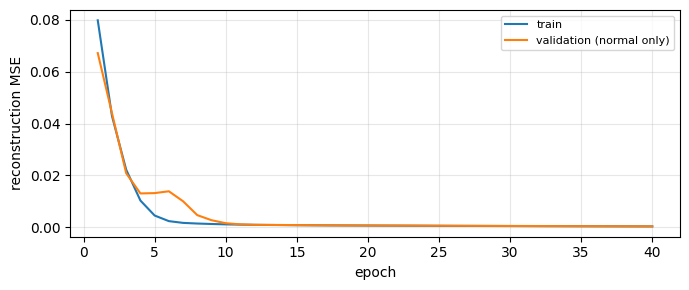

In [ ]:
best_loss, history = float('inf'), []
for epoch in range(1, EPOCHS + 1):
    model.train(); losses = []; start = time.time()
    for images, _ in train_loader:
        images = images.to(DEVICE)
        optimiser.zero_grad()
        loss = criterion(model(images), images)      # the target IS the input
        loss.backward(); optimiser.step()
        losses.append(loss.item())

    model.eval(); validation_losses = []
    with torch.inference_mode():
        for images, _ in validation_loader:
            images = images.to(DEVICE)
            validation_losses.append(criterion(model(images), images).item())

    validation_loss = float(np.mean(validation_losses))
    history.append({"epoch": epoch, "train": float(np.mean(losses)), "validation": validation_loss})

    marker = ""
    if validation_loss < best_loss:
        best_loss = validation_loss
        torch.save(model.state_dict(), WORK / 'best_model.pth'); marker = "  <- saved"
    if epoch % 2 == 0 or epoch == 1:
        print(f"epoch {epoch:3d}  train {np.mean(losses):.5f}  val {validation_loss:.5f}  "
              f"({time.time() - start:.0f}s){marker}")

import pandas as pd
frame = pd.DataFrame(history)
plt.figure(figsize=(7, 3))
plt.plot(frame.epoch, frame.train, label='train')
plt.plot(frame.epoch, frame.validation, label='validation (normal only)')
plt.xlabel('epoch'); plt.ylabel('reconstruction MSE'); plt.legend(fontsize=8); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 4. Scoring rules

**YOU DECIDE** which rule to deploy, and you must compare two:

* `mean` — average error over the image. Stable, but a small defect is
  diluted by a large expanse of correctly rebuilt background.
* `max_patch` — the worst local patch after pooling. Far more sensitive to
  small concentrated defects, and more prone to false alarms on noise.

In [ ]:
import torch.nn.functional as F

model.load_state_dict(torch.load(WORK / 'best_model.pth', map_location=DEVICE))
model.eval()


@torch.inference_mode()
def score_paths(paths, rule):
    scores = []
    loader = DataLoader(ImageListDataset(paths, transform), batch_size=BATCH_SIZE, num_workers=2)
    for images, _ in loader:
        images = images.to(DEVICE)
        error = ((images - model(images)) ** 2).mean(dim=1, keepdim=True)
        if rule == 'max_patch':
            pooled = F.avg_pool2d(error, CONFIG["patch_size"], stride=CONFIG["patch_size"] // 2)
            scores += pooled.amax(dim=(1, 2, 3)).cpu().tolist()
        else:
            scores += error.mean(dim=(1, 2, 3)).cpu().tolist()
    return np.array(scores)


from sklearn.metrics import roc_auc_score

comparison = {}
for rule in ('mean', 'max_patch'):
    normal_scores = score_paths(test_normal, rule)
    defect_scores = score_paths(test_defect, rule)
    labels = np.r_[np.zeros(len(normal_scores)), np.ones(len(defect_scores))]
    auc = roc_auc_score(labels, np.r_[normal_scores, defect_scores])
    comparison[rule] = {"auc": auc, "normal": normal_scores, "defect": defect_scores}
    print(f"{rule:10s} ROC-AUC {auc:.4f}")

BEST_RULE = max(comparison, key=lambda r: comparison[r]["auc"])
CONFIG["scoring_rule"] = BEST_RULE
print("\nDeploying:", BEST_RULE)
print("ROC-AUC is threshold-free, which is why it is the right metric for CHOOSING a rule.")

mean       ROC-AUC 1.0000
max_patch  ROC-AUC 1.0000

Deploying: mean
ROC-AUC is threshold-free, which is why it is the right metric for CHOOSING a rule.


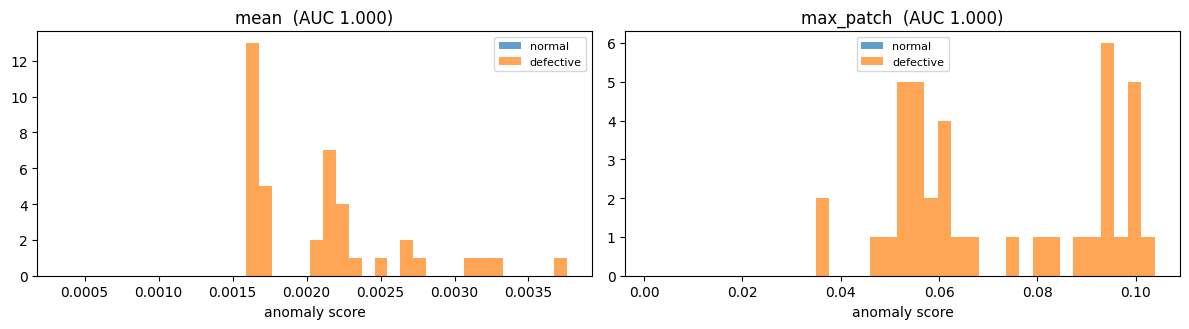

In [ ]:
# The two score distributions. The overlap between them IS the difficulty of
# your problem, and this is the most informative plot in the project.
figure, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for axis, rule in zip(axes, ('mean', 'max_patch')):
    axis.hist(comparison[rule]["normal"], bins=25, alpha=.7, label='normal')
    axis.hist(comparison[rule]["defect"], bins=25, alpha=.7, label='defective')
    axis.set_title(f"{rule}  (AUC {comparison[rule]['auc']:.3f})")
    axis.set_xlabel('anomaly score'); axis.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. The threshold — from normal validation scores only

**YOU DECIDE the percentile**, and justify it in terms of the cost of a false
alarm against the cost of a missed defect. The 95th percentile means you
accept roughly a 5% false-alarm rate on normal products.

In [ ]:
PERCENTILE = 95        # YOU DECIDE

validation_scores = score_paths(validation_paths, BEST_RULE)
CHOSEN_THRESHOLD = float(np.percentile(validation_scores, PERCENTILE))
CONFIG["anomaly_threshold"] = CHOSEN_THRESHOLD
CONFIG["threshold_rationale"] = (
    f"{PERCENTILE}th percentile of reconstruction error on {len(validation_scores)} held-out "
    f"NORMAL images, implying roughly a {100 - PERCENTILE}% false-alarm rate on good product.")
print("Threshold:", CHOSEN_THRESHOLD)
print(CONFIG["threshold_rationale"])

Threshold: 0.0003534382325597107
95th percentile of reconstruction error on 33 held-out NORMAL images, implying roughly a 5% false-alarm rate on good product.


roc_auc          1.0000
precision        0.9756
recall           1.0000
f1               0.9877
false_alarms     1
missed_defects   0
n_normal         40
n_defect         40


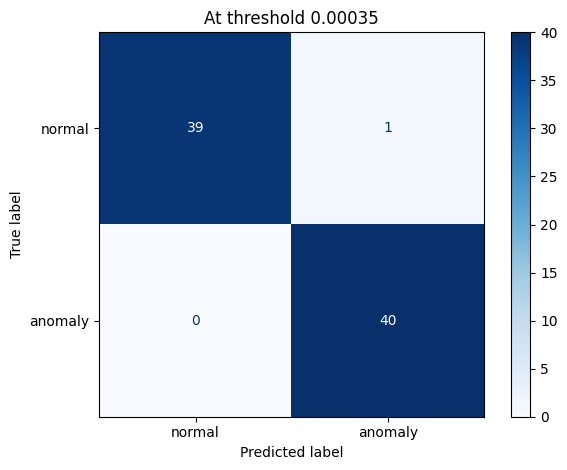

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, precision_recall_fscore_support

normal_scores = comparison[BEST_RULE]["normal"]
defect_scores = comparison[BEST_RULE]["defect"]
truth = np.r_[np.zeros(len(normal_scores)), np.ones(len(defect_scores))]
predicted = (np.r_[normal_scores, defect_scores] >= CHOSEN_THRESHOLD).astype(int)

precision, recall, f1, _ = precision_recall_fscore_support(truth, predicted, average='binary',
                                                           zero_division=0)
tn, fp, fn, tp = confusion_matrix(truth, predicted, labels=[0, 1]).ravel()
metrics = {"roc_auc": comparison[BEST_RULE]["auc"], "precision": float(precision),
           "recall": float(recall), "f1": float(f1),
           "false_alarms": int(fp), "missed_defects": int(fn),
           "n_normal": len(normal_scores), "n_defect": len(defect_scores)}
for key, value in metrics.items():
    print(f"{key:16s} {value:.4f}" if isinstance(value, float) else f"{key:16s} {value}")

ConfusionMatrixDisplay(confusion_matrix(truth, predicted),
                       display_labels=['normal', 'anomaly']).plot(cmap='Blues')
plt.title(f"At threshold {CHOSEN_THRESHOLD:.5f}"); plt.tight_layout(); plt.show()

## 6. Error analysis — look at what it missed

Missed defects are usually the small, low-contrast, texture-like ones: the
autoencoder reconstructs them too well. False alarms are usually unusual
lighting, position or orientation.

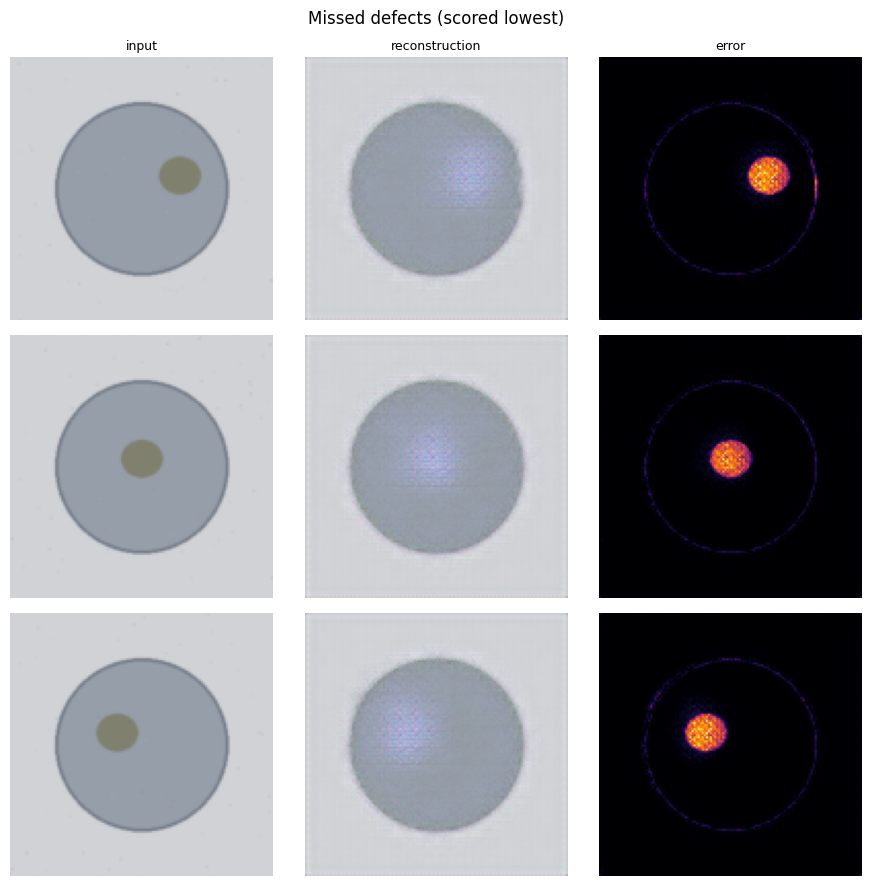

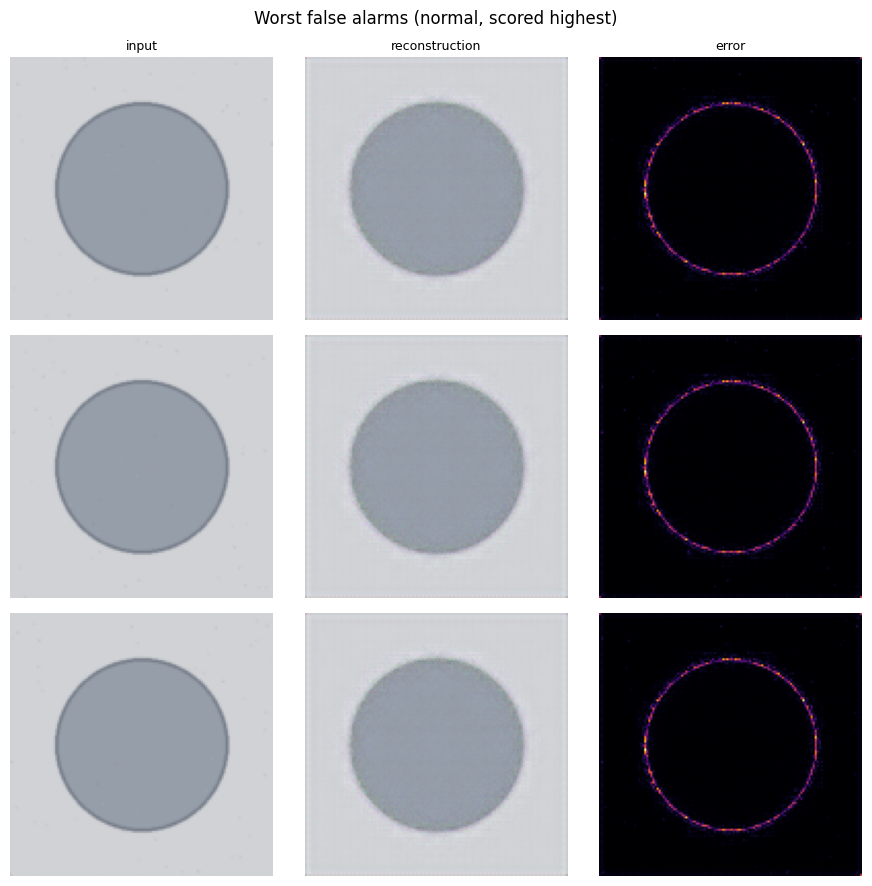

In [ ]:
@torch.inference_mode()
def inspect(path):
    image = transform(Image.open(path).convert('RGB')).unsqueeze(0).to(DEVICE)
    reconstruction = model(image)
    error = ((image - reconstruction) ** 2).mean(dim=1, keepdim=True)
    return (image[0].cpu().permute(1, 2, 0).numpy(),
            reconstruction[0].cpu().permute(1, 2, 0).numpy(),
            error[0, 0].cpu().numpy())


order = np.argsort(defect_scores)
missed = [test_defect[i] for i in order[:3]]                 # lowest-scoring defects
worst_alarms = [test_normal[i] for i in np.argsort(normal_scores)[-3:]]

for title, paths in (("Missed defects (scored lowest)", missed),
                     ("Worst false alarms (normal, scored highest)", worst_alarms)):
    figure, axes = plt.subplots(len(paths), 3, figsize=(9, 3 * len(paths)))
    for row, path in enumerate(paths):
        original, reconstruction, error = inspect(path)
        for column, (picture, label) in enumerate(
                [(original, 'input'), (reconstruction, 'reconstruction'), (error, 'error')]):
            axis = axes[row][column] if len(paths) > 1 else axes[column]
            axis.imshow(picture, cmap='inferno' if column == 2 else None); axis.axis('off')
            if row == 0:
                axis.set_title(label, fontsize=9)
    figure.suptitle(title); plt.tight_layout(); plt.show()

## 7. Export

In [ ]:
EXPORT = WORK / 'export'; EXPORT.mkdir(exist_ok=True)
torch.save(model.state_dict(), EXPORT / 'best_model.pth')
CONFIG["notes"] = json.dumps({k: (round(v, 5) if isinstance(v, float) else v)
                              for k, v in metrics.items()})
(EXPORT / 'classes.json').write_text(json.dumps(['normal', 'anomaly']))
(EXPORT / 'config.json').write_text(json.dumps(CONFIG, indent=2))

shutil.make_archive(str(WORK / 'model_artifacts'), 'zip', EXPORT)
from google.colab import files
files.download(str(WORK / 'model_artifacts.zip'))
print("Unzip into model/, then: python tools/check_setup.py")
print("Copy one normal and one defective test image into tests/fixtures/ for the demonstration.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Unzip into model/, then: python tools/check_setup.py
Copy one normal and one defective test image into tests/fixtures/ for the demonstration.


## Optional extension — feature embedding instead of reconstruction

Extract features from a pretrained CNN and score by distance to the
distribution of normal features (the PaDiM / PatchCore family). These
typically outperform reconstruction substantially, and the comparison is a
genuinely research-grade result at this scale.

## What to report

- Category, how many normal training images, and how the threshold was derived.
- ROC-AUC for BOTH scoring rules, and which you deployed.
- Precision, recall and F1 at your threshold, with false alarms and misses as counts.
- The two score distributions and their overlap.
- One missed defect and one false alarm, with the heatmaps, explained.